# 4. Evaluación final y equidad regional (RNF6)
**RetailNova — Caso 1 (SCY1102 Gestión de Proyectos de Datos, Sección 001D)** · Hurtubia · Pacheco · Curi · Gómez

Recién aquí se usa el conjunto de prueba, **una sola vez**. Se reportan métricas con el umbral convencional (0,5) y con el umbral elegido por OOF, y se audita el desempeño por región. Código en `src/evaluacion.py` y `src/equidad_regional.py`.

## 4.1 Configuración

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar src/ desde notebooks/

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as cfg

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

In [2]:
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, recall_score)
from src.modelado import cargar_modelo, cargar_seleccion, dividir_datos
from src.equidad_regional import auditar_regiones
from src.evaluacion import fila_metricas

df = pd.read_csv(cfg.CSV_PREPARADO)
pipe, sel = cargar_modelo(), cargar_seleccion()
_, X_test, _, y_test, _, reg_test = dividir_datos(df)
umbral = sel["umbral_decision"]
proba = pipe.predict_proba(X_test)[:, 1]
pred_05 = (proba >= 0.5).astype(int)
pred = (proba >= umbral).astype(int)
print("Modelo:", sel["modelo"], "· umbral OOF:", round(umbral, 4), "· clientes de prueba:", len(y_test))

Modelo: Regresión Logística · umbral OOF: 0.6415 · clientes de prueba: 10270


## 4.2 Métricas globales en prueba

In [3]:
metricas = pd.DataFrame([fila_metricas(y_test, proba, pred_05, "0,50 (referencia)"),
                         fila_metricas(y_test, proba, pred, f"{umbral:.4f} (OOF)")])
metricas

,Umbral,ROC_AUC,PR_AUC,Recall,Precisión,F1,Alertas generadas
0,"0,50 (referencia)",0.907,0.745,0.852,0.589,0.697,3565
1,0.6415 (OOF),0.907,0.745,0.740,0.646,0.690,2820


In [4]:
r = recall_score(y_test, pred)
print(f"Meta del plan: recall >= {cfg.META_RECALL:.0%} con el umbral OOF -> recall = {r:.3f}:", "CUMPLE" if r >= cfg.META_RECALL else "NO CUMPLE")

Meta del plan: recall >= 70% con el umbral OOF -> recall = 0.740: CUMPLE


**Lectura:** el umbral OOF sacrifica algo de recall frente a 0,5 a cambio de menos alertas y mayor precisión; en ambos casos se supera la meta del 70 %. El umbral se eligió con datos de entrenamiento, no con los de prueba.

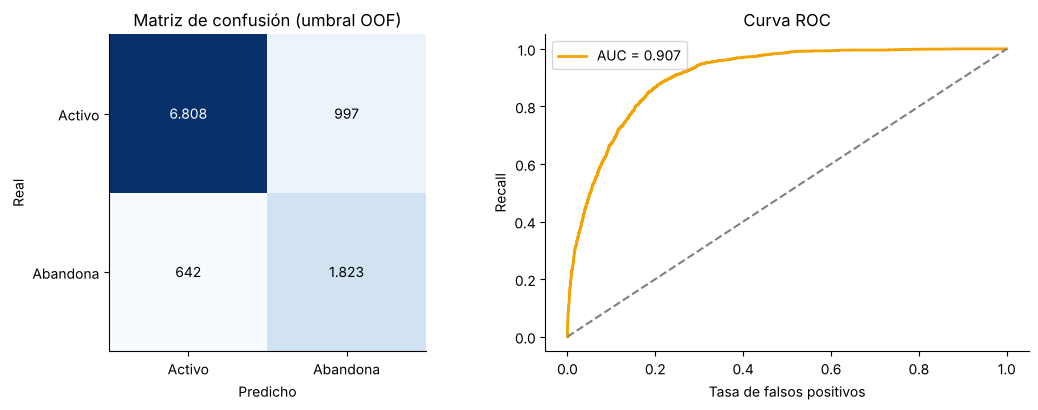

In [5]:
cm = confusion_matrix(y_test, pred)
fpr, tpr, _ = roc_curve(y_test, proba)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axs[0].text(j, i, f"{cm[i,j]:,}".replace(",", "."), ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
axs[0].set_xticks([0, 1], ["Activo", "Abandona"]); axs[0].set_yticks([0, 1], ["Activo", "Abandona"])
axs[0].set_xlabel("Predicho"); axs[0].set_ylabel("Real"); axs[0].set_title("Matriz de confusión (umbral OOF)")
axs[1].plot(fpr, tpr, color="#F4A300", lw=2, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
axs[1].plot([0, 1], [0, 1], "--", color="gray"); axs[1].set_xlabel("Tasa de falsos positivos"); axs[1].set_ylabel("Recall")
axs[1].set_title("Curva ROC"); axs[1].legend()
plt.tight_layout(); plt.show()

## 4.3 Equidad regional (RNF6 — requerimiento Must del plan)
El plan exige que la diferencia de F1 entre cada región y el F1 general sea **menor al 10 %**, para que el modelo no funcione bien solo en la Región Metropolitana (72 % de los clientes).

In [6]:
regional = auditar_regiones(y_test, pred, reg_test)
regional

,Región,N clientes (test),Tasa abandono real,F1,Recall,Diferencia vs. F1 general (%),¿Cumple RNF6 (<10%)?
0,Biobío,1180,0.226,0.708,0.775,2.600,Sí
1,Metropolitana,7387,0.237,0.689,0.743,0.100,Sí
2,Valparaíso,1703,0.262,0.680,0.704,1.400,Sí


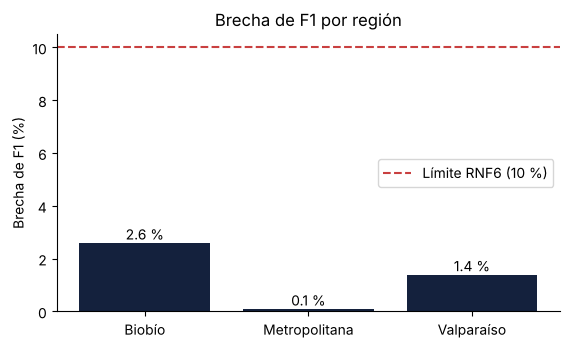

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
b = ax.bar(regional["Región"], regional["Diferencia vs. F1 general (%)"], color="#14213D")
ax.axhline(cfg.LIMITE_BRECHA_REGIONAL_PCT, color="#C94040", ls="--", label="Límite RNF6 (10 %)")
for rect, v in zip(b, regional["Diferencia vs. F1 general (%)"]): ax.text(rect.get_x()+rect.get_width()/2, v, f"{v:.1f} %", ha="center", va="bottom")
ax.set_ylabel("Brecha de F1 (%)"); ax.set_title("Brecha de F1 por región"); ax.legend()
plt.show()

**Desviación registrada (DV-1):** en una iteración intermedia Biobío no cumplía RNF6 (brecha de 12,3 %, muestra de prueba más chica). Se reforzó la validación (CV + umbral OOF) y la versión final queda con brecha máxima de 2,6 %. Con datos reales conviene volver a auditar.

## 4.4 Guardado de resultados
`evaluar` guarda métricas y auditoría regional en `output/resultados/evaluacion/`.

In [8]:
from src.evaluacion import evaluar
_ = evaluar(df, pipe, sel)

           Umbral  ROC_AUC  PR_AUC  Recall  Precisión    F1  Alertas generadas
0.50 (referencia)    0.907   0.745   0.852      0.589 0.697               3565
     0.6415 (OOF)    0.907   0.745   0.740      0.646 0.690               2820

Meta de recall del plan (>= 70 %, umbral OOF): CUMPLE
              precision    recall  f1-score   support

      Activo       0.91      0.87      0.89      7805
    Abandona       0.65      0.74      0.69      2465

    accuracy                           0.84     10270
   macro avg       0.78      0.81      0.79     10270
weighted avg       0.85      0.84      0.84     10270

       Región  N clientes (test)  Tasa abandono real    F1  Recall  Diferencia vs. F1 general (%) ¿Cumple RNF6 (<10%)?
       Biobío               1180               0.226 0.708   0.775                          2.600                   Sí
Metropolitana               7387               0.237 0.689   0.743                          0.100                   Sí
   Valparaíso           

**Siguiente:** `05_explicabilidad_shap.ipynb`.